In [15]:
import json
import time
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras

from common import contract, data, metrics, paths, plots
import mlp

plots.aplicar_estilo()

SEMENTE = contract.SEED
FEATURES = mlp.ENTRADAS

OCULTAS = (128, 64, 32)

# Valores por granularidade. A granularidade e' detectada pelo MENOR passo
# positivo do split (data.infer_freq), nao pela mediana: no split aleatorio de
# linhas horarias a mediana pula para 2h e o notebook cairia em "1d".
HIPERPARAMETROS = {
    "1d":   dict(EPOCHS=500, BATCH=32,  PACIENCIA=60, LR=1e-3),
    "1h":   dict(EPOCHS=300, BATCH=64,  PACIENCIA=40, LR=5e-4),
    "5min": dict(EPOCHS=400, BATCH=512, PACIENCIA=60, LR=3e-4),
}
# Huber delta nao e' parametro de granularidade: e' limiar na escala do residuo.
HUBER_DELTA_FRAC = 0.25

_passo = data.infer_freq(data.load_split("train"))
if _passo <= pd.Timedelta(minutes=5):
    GRANULARIDADE = "5min"
elif _passo <= pd.Timedelta(hours=1):
    GRANULARIDADE = "1h"
else:
    GRANULARIDADE = "1d"
_cfg = HIPERPARAMETROS[GRANULARIDADE]
EPOCHS, BATCH, PACIENCIA, LR = (
    _cfg["EPOCHS"], _cfg["BATCH"], _cfg["PACIENCIA"], _cfg["LR"])

keras.utils.set_random_seed(SEMENTE)
np.random.seed(SEMENTE)

print("tensorflow", tf.__version__, "| keras", keras.__version__)
print(f"entradas: {len(FEATURES)} -> {', '.join(FEATURES)}")
print("splits  : train (2021..2024H1) | calibration (2024H2) | test (2025)")
print(f"granularidade: {GRANULARIDADE} | EPOCHS={EPOCHS} BATCH={BATCH} "
      f"PACIENCIA={PACIENCIA} LR={LR:g}")

tensorflow 2.21.0 | keras 3.15.1
entradas: 3 -> temperatura_ambiente, ghit, jacques
splits  : train (2021..2024H1) | calibration (2024H2) | test (2025)
granularidade: 1h | EPOCHS=300 BATCH=64 PACIENCIA=40 LR=0.0005


In [16]:
treino = data.load_split("train")
calibracao = data.load_split("calibration")
teste = data.load_split("test")
ALVO = contract.TARGET

# Min-max ajustado SO no treino (2021..2024H1); calibracao e teste usam as
# mesmas constantes. O maximo vira minimo + 1 numa coluna constante.
minimo = treino[list(FEATURES)].min()
maximo = treino[list(FEATURES)].max()
maximo = maximo.where(maximo > minimo, minimo + 1.0)

def escala(d):
    return ((d[list(FEATURES)] - minimo) / (maximo - minimo)).to_numpy(np.float32)

X_tre, y_tre = escala(treino), treino[ALVO].to_numpy(np.float32)
X_cal, y_cal = escala(calibracao), calibracao[ALVO].to_numpy(np.float32)
X_tes, y_tes = escala(teste), teste[ALVO].to_numpy(np.float32)

# O prep entrega PCA CRU (potencia media em kW). O Box-Cox e' especifico do MLP:
# o lambda e' ajustado SO no treino e aplicado a calibracao e ao teste. A inversa
# (inv_boxcox) devolve kW para metrica, calibracao e graficos.
from scipy.stats import boxcox
from scipy.special import inv_boxcox

assert (y_tre > 0).all(), "Box-Cox exige alvo > 0 (o prep removeu os zeros)"
y_tre_bc, LAMBDA = boxcox(y_tre)
y_cal_bc = boxcox(y_cal, lmbda=LAMBDA)
y_tes_bc = boxcox(y_tes, lmbda=LAMBDA)

# A inversa so' existe para 1 + lambda*y > 0. O clip usa o dominio valido e a
# faixa do treino; target_limits() NAO serve (a folga de 5% cai fora do dominio).
DOMINIO_MIN = (-1.0 / LAMBDA + 1e-9) if abs(LAMBDA) > 1e-8 else -np.inf
CLIP_BC = (max(float(y_tre_bc.min()), DOMINIO_MIN), float(y_tre_bc.max()))

def para_kw(pred_bc):
    """Box-Cox -> kW, com clip seguro antes da inversa."""
    return inv_boxcox(np.clip(pred_bc, *CLIP_BC), LAMBDA)

HUBER_DELTA = HUBER_DELTA_FRAC * float(
    np.quantile(y_tre_bc, .75) - np.quantile(y_tre_bc, .25))

for nome, y, y_bc in (("treino", y_tre, y_tre_bc),
                      ("calibracao", y_cal, y_cal_bc),
                      ("teste", y_tes, y_tes_bc)):
    print(f"{nome:10} {len(y):6} amostras | PCA {y.min():7.2f}..{y.max():7.2f} kW "
          f"| Box-Cox {y_bc.min():7.3f}..{y_bc.max():7.3f}")

PCA_MIN, PCA_MAX = data.physical_target_limits()

assert len(X_cal) > 100, f"calibracao ficou com so {len(X_cal)} amostras"
assert X_tre.dtype == np.float32 and X_cal.dtype == np.float32
print("OK: X em [0, 1] (min-max ajustado so no treino 2021..2024H1)")
print(f"lambda Box-Cox = {LAMBDA:.6f} | HUBER_DELTA = {HUBER_DELTA:.3f} (espaco Box-Cox)")

treino      78881 amostras | PCA    0.00..   2.00 kW | Box-Cox  -1.570..  0.863
calibracao  11335 amostras | PCA    0.00..   1.99 kW | Box-Cox  -1.570..  0.856
teste       22619 amostras | PCA    0.00..   2.00 kW | Box-Cox  -1.570..  0.860
OK: X em [0, 1] (min-max ajustado so no treino 2021..2024H1)
lambda Box-Cox = 0.612110 | HUBER_DELTA = 0.247 (espaco Box-Cox)


In [17]:
camadas = [keras.layers.Input(shape=(len(FEATURES),), name="features")]
for i, n in enumerate(OCULTAS):
    camadas.append(keras.layers.Dense(n, activation="gelu", name=f"oculta_{i}"))
    camadas.append(keras.layers.Dropout(0.1))
# A saida da rede esta no espaco Box-Cox (nao em kW): media_y e' a media do
# alvo transformado, e a inversa/offset sao aplicados fora do modelo.
media_y = float(y_tre_bc.mean())
camadas.append(keras.layers.Dense(
    1, name="pca_kw",
    bias_initializer=keras.initializers.Constant(media_y)))

modelo = keras.Sequential(camadas, name="knob_senses_pca")
modelo.compile(
    optimizer=keras.optimizers.Adam(LR),
    loss=keras.losses.Huber(delta=HUBER_DELTA),
    metrics=[keras.metrics.RootMeanSquaredError(name="rmse"), "mae"],
)
modelo.summary()

Model: "knob_senses_pca"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_0 (Dense)                │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pca_kw (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,881 (42.50 KB)

 Trainable params: 10,881 (42.50 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
chamadas = [
    keras.callbacks.EarlyStopping(monitor="val_mae", patience=PACIENCIA*2,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=8 ,
                                      min_lr=1e-8, verbose=1),
]

t0 = time.perf_counter()
# Validacao temporal (2024H2), nao o split aleatorio por linha. O alvo aqui e'
# o Box-Cox do treino; a metrica final do notebook e' convertida para kW.
historico = modelo.fit(
    X_tre, y_tre_bc,
    validation_data=(X_cal, y_cal_bc),
    epochs=EPOCHS, batch_size=BATCH, callbacks=chamadas, verbose=0,
)
print(f"treino da rede: {time.perf_counter() - t0:.1f} s")
print(f"parou na epoca {len(historico.history['loss'])} "
      f"(melhor val_mae {min(historico.history['val_mae']):.5f}, espaco Box-Cox)")

I0000 00:00:1793899846.489236 2074535 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_264226__.15
I0000 00:00:1793899848.107519 2074535 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_264226__.15
I0000 00:00:1793899848.255786 2074535 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1793899848.518837 2074535 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1793899848.728915 2074535 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a


Epoch 11: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 19: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 27: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 35: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 43: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

Epoch 51: ReduceLROnPlateau reducing learning rate to 7.812500371073838e-06.

Epoch 59: ReduceLROnPlateau reducing learning rate to 3.906250185536919e-06.

Epoch 67: ReduceLROnPlateau reducing learning rate to 1.9531250927684596e-06.

Epoch 75: ReduceLROnPlateau reducing learning rate to 9.765625463842298e-07.

Epoch 83: ReduceLROnPlateau reducing learning rate to 4.882812731921149e-07.
Epoch 83: early stopping
Restoring model weights from the end of the best epoch: 3.
treino da rede: 79.5 s
parou na epoca 83 (melhor val_mae 0.14944, espaco Box-Cox)


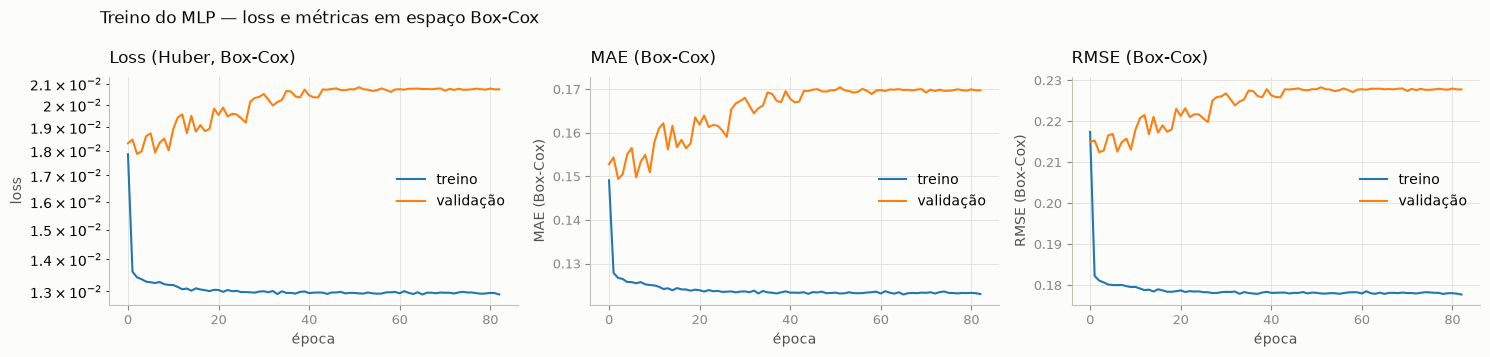

In [19]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
for eixo, chave, titulo, ylabel in (
    (eixos[0], "loss", "Loss (Huber, Box-Cox)", "loss"),
    (eixos[1], "mae", "MAE (Box-Cox)", "MAE (Box-Cox)"),
    (eixos[2], "rmse", "RMSE (Box-Cox)", "RMSE (Box-Cox)"),
):
    eixo.plot(historico.history[chave], label="treino")
    eixo.plot(historico.history[f"val_{chave}"], label="validação")
    plots.enfeitar(eixo, titulo, "época", ylabel)
    eixo.legend(frameon=False)
eixos[0].set_yscale("log")
fig.suptitle("Treino do MLP — loss e métricas em espaço Box-Cox", x=0.07, ha="left",
             color=plots.TINTA)
fig.tight_layout()
plt.show()

In [20]:
# Calibracao do vies em kW: offset = media(real - previsto) na calibracao
# (2024H2). A saida da rede esta em Box-Cox, entao NAO da' para somar o offset no
# bias da camada de saida; invertemos a previsao e medimos o vies em kW.
pred_cal_bc = modelo.predict(X_cal, batch_size=512, verbose=0).ravel()
y_cal_kw = inv_boxcox(y_cal_bc, LAMBDA)
OFFSET_CALIBRACAO = float(np.mean(y_cal_kw - para_kw(pred_cal_bc)))
print(f"offset de calibracao (2024H2, kW): {OFFSET_CALIBRACAO:+.4f}")

# Checkpoint Keras: salva o modelo treinado e recarrega antes do teste.
# O modelo salvo devolve BOX-COX; a inversa, o clip fisico e o offset vao no
# sidecar abaixo (e no normalizacao.json do export, se ele for chamado).
SAIDA = paths.EXPORT_MLP
SAIDA.mkdir(parents=True, exist_ok=True)
caminho_modelo = SAIDA / "modelo.keras"
modelo.save(caminho_modelo)

modelo_carregado = keras.models.load_model(caminho_modelo, compile=False)
n = min(256, len(X_tes))
assert np.allclose(modelo.predict(X_tes[:n], verbose=0),
                   modelo_carregado.predict(X_tes[:n], verbose=0), atol=1e-6)

transformacao = {
    "tipo": "boxcox",
    "lambda": float(LAMBDA),
    "inversa": "y_kw = (1 + lambda*y_bc)**(1/lambda)",
    "clip_boxcox": [float(CLIP_BC[0]), float(CLIP_BC[1])],
    "offset_kw": float(OFFSET_CALIBRACAO),
    "pca_min_kw": float(PCA_MIN),
    "pca_max_kw": float(PCA_MAX),
    "features": list(FEATURES),
    "ajustado_em": "treino 2021..2024H1",
    "calibracao_em": "2024H2",
    "pos_processamento": "clip_boxcox -> inv_boxcox -> + offset_kw -> clip(pca_min_kw, pca_max_kw)",
}
caminho_transformacao = SAIDA / "transformacao_alvo.json"
caminho_transformacao.write_text(
    json.dumps(transformacao, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

print(f"modelo salvo e recarregado: {caminho_modelo} "
      f"({caminho_modelo.stat().st_size / 1024:.1f} KB)")
print(f"transformacao salva: {caminho_transformacao}")

I0000 00:00:1793899925.795814 2074539 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1793899926.079150 2074539 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


offset de calibracao (2024H2, kW): -0.0600
modelo salvo e recarregado: /home/scorel/Documents/knob-senses/dist/modelo.keras (164.1 KB)
transformacao salva: /home/scorel/Documents/knob-senses/dist/transformacao_alvo.json


I0000 00:00:1793899927.365149 2074535 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1793899927.657384 2074535 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


keras (MLP)          MAE 0.1110 kW | RMSE 0.1561 kW | R2 0.9124 | vies +0.0058 kW


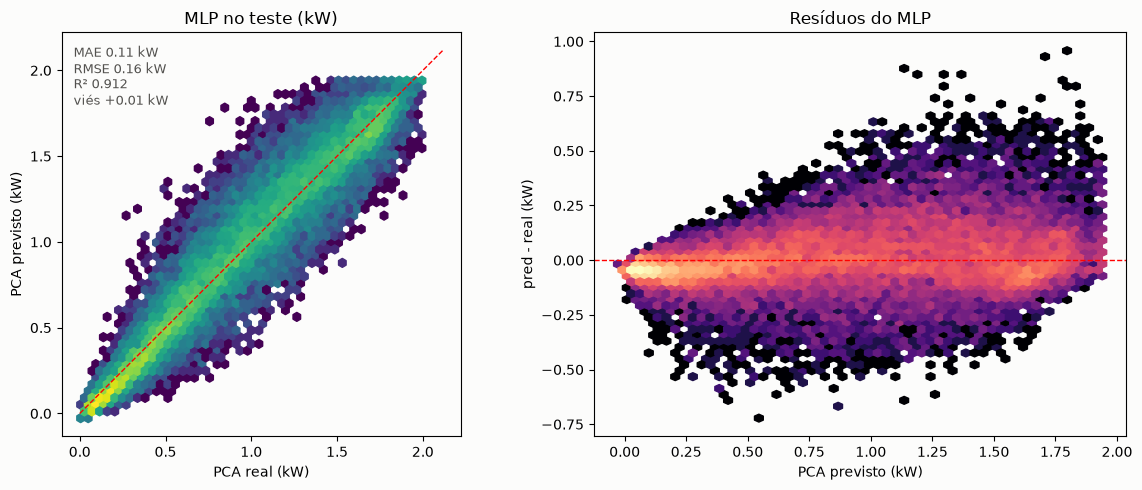

In [21]:
pred_bc = modelo_carregado.predict(X_tes, batch_size=512, verbose=0).ravel()
pred = para_kw(pred_bc) + OFFSET_CALIBRACAO   # Box-Cox -> kW -> calibracao
y_tes_kw = inv_boxcox(y_tes_bc, LAMBDA)

resultado = metrics.evaluate("keras (MLP)", y_tes_kw, pred,
                             pca_min=PCA_MIN, pca_max=PCA_MAX)

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
plots.hexbin_real_vs_pred(eixos[0], y_tes_kw, pred, "MLP no teste (kW)")
plots.hexbin_residuo(eixos[1], y_tes_kw, pred, "Resíduos do MLP")
eixos[1].set_ylabel("pred - real (kW)")
texto = chr(10).join([
    f"MAE {resultado['MAE (kW)']:.2f} kW",
    f"RMSE {resultado['RMSE (kW)']:.2f} kW",
    f"R² {resultado['R2']:.3f}",
    f"viés {resultado['vies (kW)']:+.2f} kW",
])
eixos[0].text(0.03, 0.97, texto, transform=eixos[0].transAxes, va="top",
              color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
fig.tight_layout()
plt.show()